In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import time

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
%matplotlib inline


In [6]:
# If you have an internet connection
# We can load the full data set via the Scikit-learn data_set package

from sklearn.datasets import fetch_openml
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=True)
# X.iloc[:5000,:].to_csv('./data/mnist_7000_data.csv', index=False)
# y.iloc[:5000].to_csv('./data/mnist_7000_labels.csv', index=False)


In [7]:
#X = pd.read_csv('../data/mnist_7000_data.csv', index_col=False)
#y = pd.read_csv('../data/mnist_7000_labels.csv', index_col=False)
X.shape, y.shape

((70000, 784), (70000,))

Let's see how many different classes we have in the dataset

<Axes: xlabel='class'>

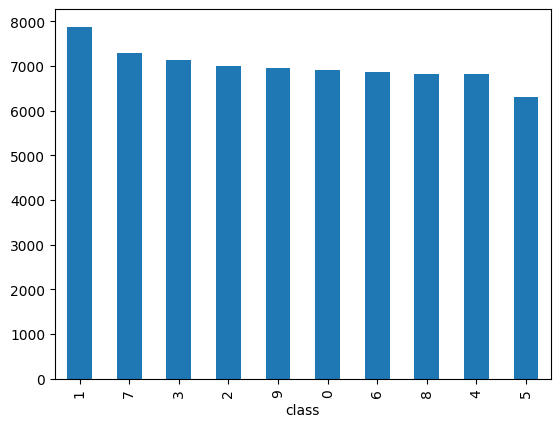

In [9]:
y.value_counts().plot.bar()

Each row in X contains 784 features - representing the 28x28 pixels pictures. In order to view the pictures, we will rescale the 784 vector into the 2D matrix of 28x28 and then use the Matplotlib API for displaying the images. Let's view the first 9 images of the dataset


In [10]:
X

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


IndexingError: Too many indexers

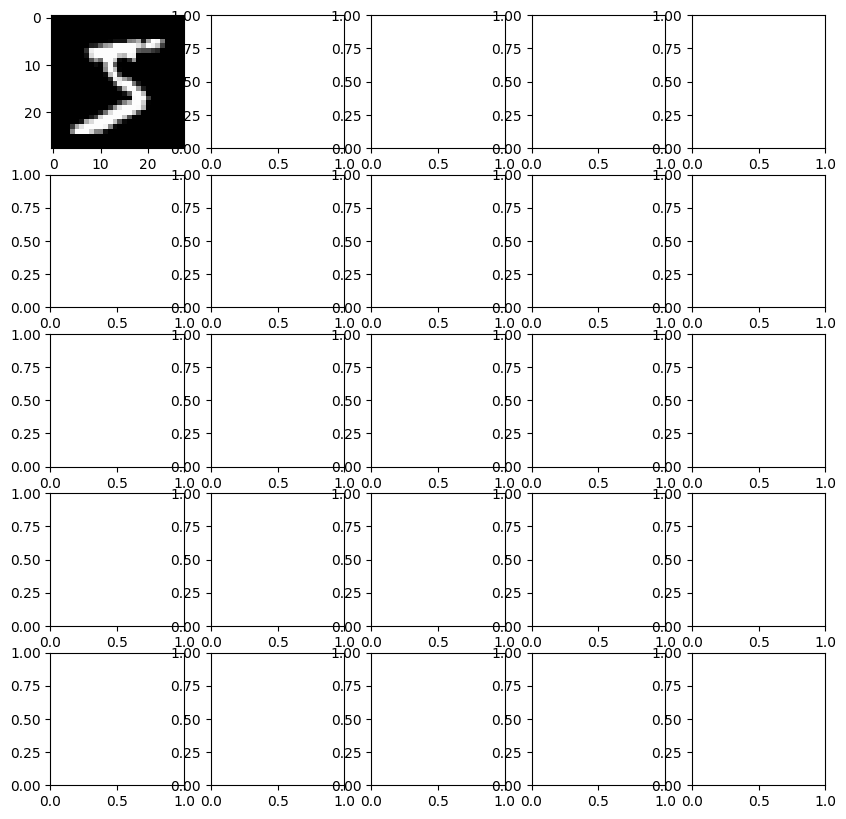

In [11]:
fig, ax = plt.subplots(nrows=5, ncols=5, figsize=(10, 10))
for i in range(5):
    for j in range(5):
        ax[i, j].imshow(X.iloc[i*5+j, :].values.reshape((28, 28)), cmap='gray')
        ax[i, j].set_title(f'Label: {y.iloc[i*5+j, 0]}')

In [12]:
n_train = 4500
X_train = X.values[:n_train, :]
X_test = X.values[n_train:, :]
y_train = y.values.ravel()[:n_train]
y_test = y.values.ravel()[n_train:]

In this part we will rescale the features of the model - dividing it by 255 (the largest possible value of the pixel) to bring everythiong into the range of 0 to 1

In [13]:
X_train = (X_train / 255).astype('float32')
X_test = (X_test / 255).astype('float32')


In [14]:
clf = linear_model.LogisticRegression(random_state=0).fit(X_train, y_train)
print(f'Trian accuracy of the model: {clf.score(X_train, y_train)}')
print(f'Test accuracy of the model: {clf.score(X_test, y_test)}')

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Trian accuracy of the model: 0.988
Test accuracy of the model: 0.8883511450381679


In order to show the in-correctly classified examples, we can use the following

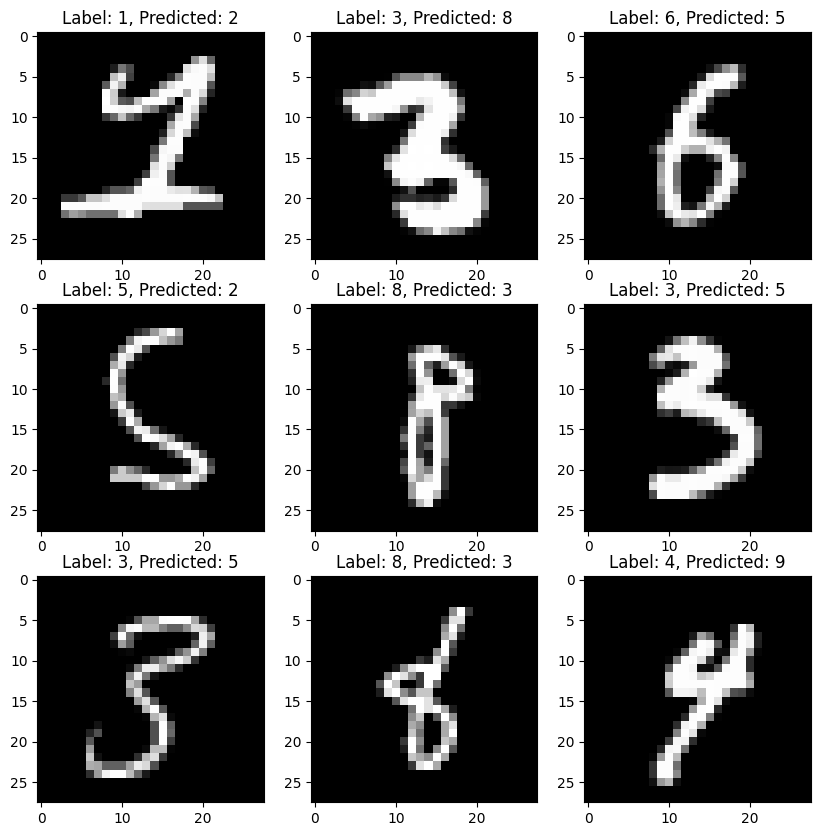

In [26]:
y_predicted = clf.predict(X_test)
X_test_wrong = X_test[y_predicted != y_test]
y_test_wrong = y_test[y_predicted != y_test]
y_predicted_wrong = y_predicted[y_predicted != y_test]

fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))
for i in range(3):
    for j in range(3):
        ax[i, j].imshow(X_test_wrong[i*3+j, :].reshape((28, 28)), cmap='gray')
        ax[i, j].set_title(f'Label: {y_test_wrong[i*3+j]}, Predicted: {y_predicted_wrong[i*3+j]}')


In this section we will write our own implementation of the Neural Network from scratch - using only Numpy


In [27]:
class DeepNeuralNetwork():
    def __init__(self, sizes, epochs=10, l_rate=0.001, filename=None):
        self.sizes = sizes
        self.epochs = epochs
        self.l_rate = l_rate

        # we save all parameters in the neural network in this dictionary
        if filename is None:
            self.params = self.initialization()
        else:
            self.deserialize(filename)

    def serialize(self, filename):
        np.savez(filename, **self.params)

    def deserialize(self, filename):
        self.params = dict(np.load(filename, allow_pickle=True))

    def sigmoid(self, x, derivative=False):
        if derivative:
            return (np.exp(-x)) / ((np.exp(-x) + 1) ** 2)
        return 1 / (1 + np.exp(-x))

    def identity(self, x, derivative=False):
        if derivative:
            return 1
        return x

    def relu(self, x, derivative=False):
        if derivative:
            if x<0:
                return 0
            else:
                return 1
        if x<0:
            return 0
        return x

    def activation(self, x, derivative=False):
        #return self.sigmoid(x, derivative)
        return self.identity(x, derivative)

    def softmax(self, x, derivative=False):
        # Numerically stable with large exponentials
        exps = np.exp(x - x.max())
        if derivative:
            return exps / np.sum(exps, axis=0) * (1 - exps / np.sum(exps, axis=0))
        return exps / np.sum(exps, axis=0)

    def initialization(self):
        # number of nodes in each layer
        input_layer = self.sizes[0]
        hidden_1 = self.sizes[1]
        hidden_2 = self.sizes[2]
        output_layer = self.sizes[3]

        params = {
            'W1': np.random.randn(hidden_1, input_layer) * np.sqrt(1. / hidden_1),
            'W2': np.random.randn(hidden_2, hidden_1) * np.sqrt(1. / hidden_2),
            'W3': np.random.randn(output_layer, hidden_2) * np.sqrt(1. / output_layer)
        }

        return params

    def forward_pass(self, x_train):
        params = self.params

        # input layer activations becomes sample
        params['A0'] = x_train

        # input layer to hidden layer 1
        params['Z1'] = np.dot(params["W1"], params['A0'])
        params['A1'] = self.activation(params['Z1'])

        # hidden layer 1 to hidden layer 2
        params['Z2'] = np.dot(params["W2"], params['A1'])
        params['A2'] = self.activation(params['Z2'])

        # hidden layer 2 to output layer
        params['Z3'] = np.dot(params["W3"], params['A2'])
        params['A3'] = self.softmax(params['Z3'])

        return params['A3']

    def backward_pass(self, y_train, output):
        '''
            This is the backpropagation algorithm, for calculating the updates
            of the neural network's parameters.

            Note: There is a stability issue that causes warnings. This is
                  caused  by the dot and multiply operations on the huge arrays.

                  RuntimeWarning: invalid value encountered in true_divide
                  RuntimeWarning: overflow encountered in exp
                  RuntimeWarning: overflow encountered in square
        '''

        params = self.params
        change_w = {}

        # Calculate W3 update
        error = 2 * (output - y_train) / output.shape[0] * self.softmax(params['Z3'], derivative=True)
        change_w['W3'] = np.outer(error, params['A2'])

        # Calculate W2 update
        error = np.dot(params['W3'].T, error) * self.activation(params['Z2'], derivative=True)
        change_w['W2'] = np.outer(error, params['A1'])

        # Calculate W1 update
        error = np.dot(params['W2'].T, error) * self.activation(params['Z1'], derivative=True)
        change_w['W1'] = np.outer(error, params['A0'])

        return change_w

    def update_network_parameters(self, changes_to_w):
        '''
            Update network parameters according to update rule from
            Stochastic Gradient Descent.

            θ = θ - η * ∇J(x, y),
                theta θ:            a network parameter (e.g. a weight w)
                eta η:              the learning rate
                gradient ∇J(x, y):  the gradient of the objective function,
                                    i.e. the change for a specific theta θ

            For each W1, W2, W3:
                W1 = W1 - learning_rate * GradientOf(W1)
                W2 = W2 - learning_rate * GradientOf(W2)
                W3 = W3 - learning_rate * GradientOf(W3)
        '''
        for key, value in changes_to_w.items():
            self.params[key] -= self.l_rate * value

    def compute_accuracy(self, x_val, y_val):
        '''
            This function does a forward pass of x, then checks if the indices
            of the maximum value in the output equals the indices in the label
            y. Then it sums over each prediction and calculates the accuracy.
        '''
        predictions = []

        for x, y in zip(x_val, y_val):
            output = self.forward_pass(x)
            pred = np.argmax(output)
            predictions.append(pred == np.argmax(y))

        return np.mean(predictions)

    def train(self, x_train, y_train, x_val, y_val):
        start_time = time.time()
        for iteration in range(self.epochs):
            for x, y in zip(x_train, y_train):
                output = self.forward_pass(x)
                changes_to_w = self.backward_pass(y, output)
                self.update_network_parameters(changes_to_w)

            accuracy = self.compute_accuracy(x_val, y_val)
            print('Epoch: {0}, Time Spent: {1:.2f}s, Accuracy: {2:.2f}%'.format(
                iteration + 1, time.time() - start_time, accuracy * 100
            ))



In [17]:
from sklearn.preprocessing import OneHotEncoder

def preprocess_labels(y_train, y_test):
    encoder = OneHotEncoder(sparse_output=False).fit(y_train.reshape((-1, 1)))
    return encoder.transform(y_train.reshape((-1, 1))), encoder.transform(y_test.reshape((-1, 1)))

y_train_onehot, y_test_onehot = preprocess_labels(y_train, y_test)


In [18]:
filename = 'mnist_15epochs_sigmoid.npz'
dnn = DeepNeuralNetwork(sizes=[784, 128, 64 , 10,4], epochs=6, l_rate=0.001)
dnn.train(X_train, y_train_onehot, X_test, y_test_onehot)
dnn.serialize(filename)

Epoch: 1, Time Spent: 12.74s, Accuracy: 25.72%
Epoch: 2, Time Spent: 21.17s, Accuracy: 42.40%
Epoch: 3, Time Spent: 27.46s, Accuracy: 51.81%
Epoch: 4, Time Spent: 32.94s, Accuracy: 60.13%
Epoch: 5, Time Spent: 39.33s, Accuracy: 67.18%
Epoch: 6, Time Spent: 46.07s, Accuracy: 71.29%


Let's compute the accuracy of the network and visualize the predictions

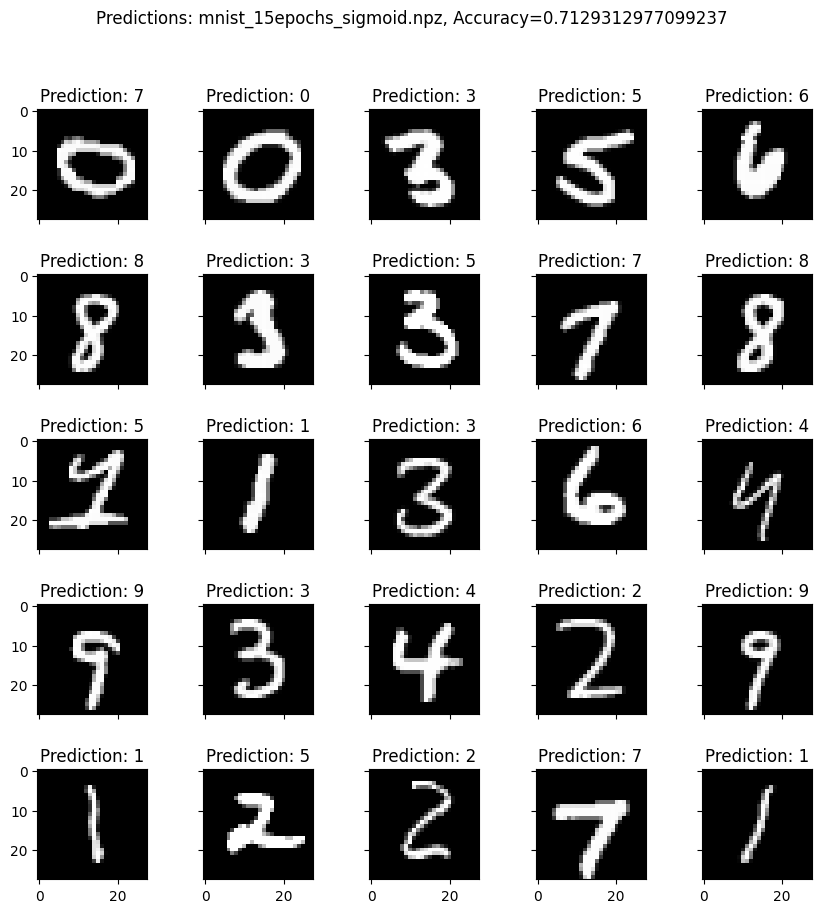

In [19]:
acc = dnn.compute_accuracy(X_test, y_test_onehot)
fig = plt.figure(figsize=(10, 10))
fig.suptitle(f'Predictions: {filename}, Accuracy={acc}')
gs = fig.add_gridspec(5, 5, hspace=0.5, wspace=0.5)
ax = gs.subplots(sharex=True, sharey=True)
for nr in range(5):
    for nc in range(5):
        ax[nr, nc].imshow(X_test[nr + 5 * nc].reshape((28, 28)), cmap='gray')
        prediction = np.argmax(dnn.forward_pass(X_test[nr + 5 * nc]))
        ax[nr, nc].set_title(f'Prediction: {prediction}')
plt.show()


In [20]:
!pip install tensorflow


In [21]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten, InputLayer

num_classes=10

We will use the Sequential API of Keras. A Sequential model is appropriate for a plain stack of layers where each layer has exactly one input tensor and one output tensor.

* The first layer of the Network accepts the image. So we initialize it as accepting the images of the size of the MNIST images - in this case array of the length 784
* The second layer of the Network is just the softmax layer - making the classification

This architecture is equivalent to the simple Logistic regression as we built before with scikit-learn


In [22]:
model = Sequential()
model.add(InputLayer(input_shape=X_train.shape[1:]))
model.add(Dense(num_classes, activation='softmax'))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


The arcitecture looks like the following:

[![logistic_network](./img/logistic_network.png)](https://www.tensorflow.org/)

The images were already transoformed to the vectors. The output of the network is a vector of 10 numbers. The matrix W that we actually learn is the matrix of the size 10x784 - transforming the input of 784 numbers into vector of 10. The bias vector b is of size 10. Therefore, we have the total paramters of the network to learn:
$$
784*10 + 10 = 7850
$$
as is estimated in the output of the function ```summary```.



In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Convert class vectors to binary class matrices. This is called one hot encoding.
y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_test_cat = keras.utils.to_categorical(y_test, num_classes)


In [34]:
from tensorflow.keras.optimizers import Adam
model.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.001), # כאן הסרנו את הרווח לפני ה-=
              metrics=['accuracy'])

history = model.fit(X_train, y_train_cat,
              batch_size=32,
              epochs=20,
              validation_data=(X_test, y_test_cat),
              shuffle=True)

model.save(r'/content/drive/MyDrive/ML/קורסים אולטרה קוד/Computer Vision/תרגול/שיעור 5/data/model_softmax.h5')
pd.DataFrame(history.history).to_csv('/content/drive/MyDrive/ML/קורסים אולטרה קוד/Computer Vision/תרגול/שיעור 5/data/history_softmax.csv')


Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.6862 - loss: 1.2717 - val_accuracy: 0.8254 - val_loss: 0.7859
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8644 - loss: 0.6172 - val_accuracy: 0.8588 - val_loss: 0.5693
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8880 - loss: 0.4753 - val_accuracy: 0.8756 - val_loss: 0.4894
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8998 - loss: 0.4069 - val_accuracy: 0.8816 - val_loss: 0.4442
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9080 - loss: 0.3662 - val_accuracy: 0.8869 - val_loss: 0.4160
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9122 - loss: 0.3375 - val_accuracy: 0.8898 - val_loss: 0.3987
Epoch 7/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9178 - loss: 0.3160 - val_accuracy: 0.8913 - val_loss: 0.3863
Epoch 8/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9216 - loss: 0.2982 - val_accu

## FNN - Fully connected Neural Network

Let's try to make a Netowrk more complex, by adding the new Fully connected layers


In [35]:
model_fnn = Sequential()
model_fnn.add(InputLayer(input_shape=X_train.shape[1:]))
model_fnn.add(Dense(256, activation='relu'))
model_fnn.add(Dense(128, activation='relu'))
model_fnn.add(Dense(64, activation='relu'))
model_fnn.add(Dense(num_classes, activation='softmax'))
model_fnn.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model_fnn.compile(loss='categorical_crossentropy',
              optimizer=keras.optimizers.SGD(),
              metrics=['accuracy'])

history_fnn = model_fnn.fit(X_train, y_train_cat,
              batch_size=32,
              epochs=20,
              validation_data=(X_test, y_test_cat),
              shuffle=True)

model_fnn.save(r'/content/drive/MyDrive/ML/קורסים אולטרה קוד/Computer Vision/תרגול/שיעור 5/data/model_softmax_fnn.h5')
pd.DataFrame(history_fnn.history).to_csv('/content/drive/MyDrive/ML/קורסים אולטרה קוד/Computer Vision/תרגול/שיעור 5/data/history_softmax_fnn.csv')


Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.3491 - loss: 2.0945 - val_accuracy: 0.5471 - val_loss: 1.8187
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6776 - loss: 1.4157 - val_accuracy: 0.7397 - val_loss: 1.0877
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.8158 - loss: 0.8348 - val_accuracy: 0.8166 - val_loss: 0.7252
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8578 - loss: 0.5860 - val_accuracy: 0.8518 - val_loss: 0.5636
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8809 - loss: 0.4692 - val_accuracy: 0.8591 - val_loss: 0.4969
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8898 - loss: 0.4037 - val_accuracy: 0.8752 - val_loss: 0.4456
Epoch 7/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9080 - loss: 0.3582 - val_accuracy: 0.8754 - val_loss: 0.4301
Epoch 8/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9147 - loss: 0.3287 - val_acc




We built the 2 Neural Networks: a simple 1 layer and an FNN with 3 layers. Let's plot the graphs of accuracy of both models. Let's see what is the objecto of history


In [37]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

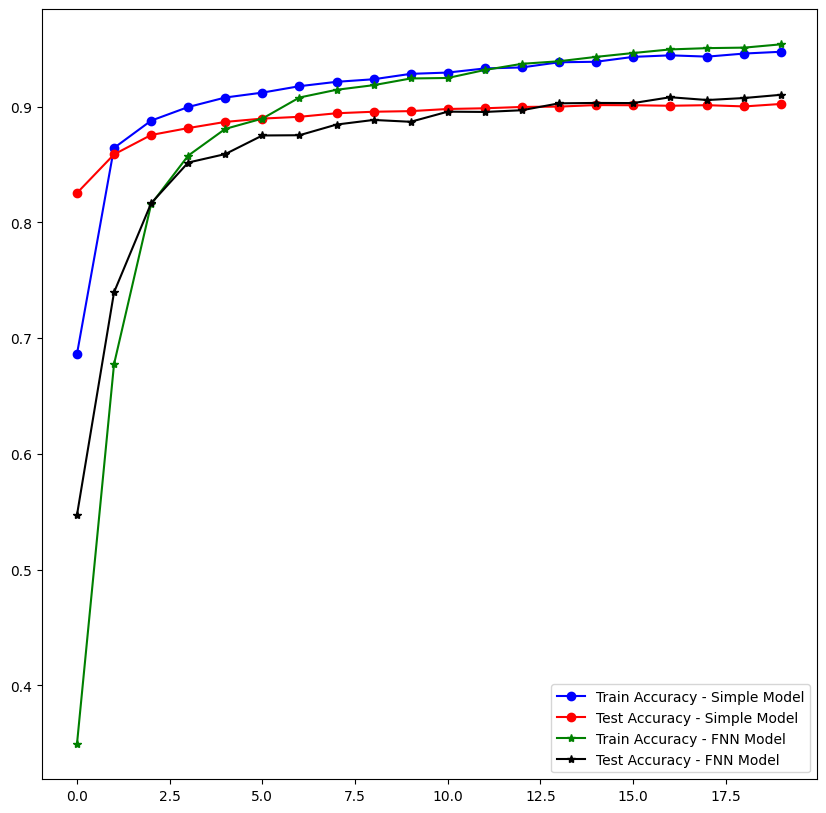

In [38]:
plt.figure(figsize=(10, 10))
plt.plot(history.history['accuracy'], 'bo-', label='Train Accuracy - Simple Model')
plt.plot(history.history['val_accuracy'], 'ro-', label='Test Accuracy - Simple Model')
plt.plot(history_fnn.history['accuracy'], 'g*-', label='Train Accuracy - FNN Model')
plt.plot(history_fnn.history['val_accuracy'], 'k*-', label='Test Accuracy - FNN Model')
plt.legend()

# Excercise 2

Try to improve the result with the FNN by

* Adding more layers
* Changing the optimizer to Adam
* Increasing the number of epochs


In [42]:
model_improved = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_improved.compile(optimizer='adam',
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

history_improved = model_improved.fit(X_train, y_train_cat,
                                      batch_size=32,
                                      epochs=40,
                                      validation_data=(X_test, y_test_cat),
                                      shuffle=True)

Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


141/141 ━━━━━━━━━━━━━━━━━━━━ 21s 130ms/step - accuracy: 0.8364 - loss: 0.5566 - val_accuracy: 0.9077 - val_loss: 0.3080
Epoch 2/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.9438 - loss: 0.1953 - val_accuracy: 0.9225 - val_loss: 0.2525
Epoch 3/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.9682 - loss: 0.1078 - val_accuracy: 0.9278 - val_loss: 0.2434
Epoch 4/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.9778 - loss: 0.0722 - val_accuracy: 0.9252 - val_loss: 0.2686
Epoch 5/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9871 - loss: 0.0485 - val_accuracy: 0.9373 - val_loss: 0.2362
Epoch 6/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.9844 - loss: 0.0478 - val_accuracy: 0.9262 - val_loss: 0.2929
Epoch 7/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.9916 - loss: 0.0328 - val_accuracy: 0.9408 - val_loss: 0.2364
Epoch 8/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.9960 - loss: 0.0146 - val_accuracy: 0

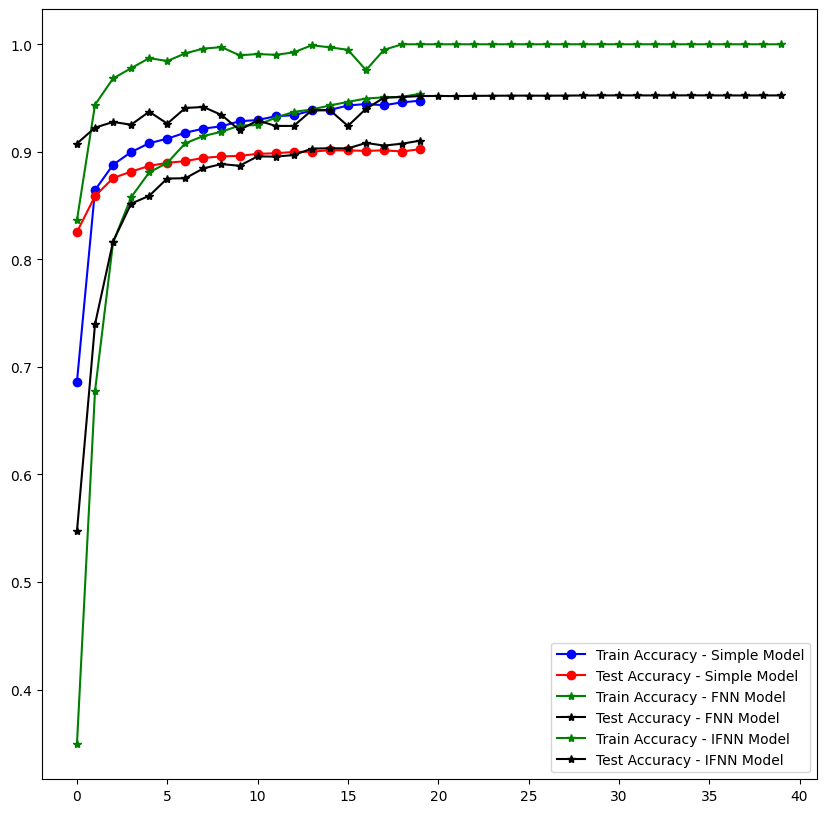

In [43]:
plt.figure(figsize=(10, 10))
plt.plot(history.history['accuracy'], 'bo-', label='Train Accuracy - Simple Model')
plt.plot(history.history['val_accuracy'], 'ro-', label='Test Accuracy - Simple Model')
plt.plot(history_fnn.history['accuracy'], 'g*-', label='Train Accuracy - FNN Model')
plt.plot(history_fnn.history['val_accuracy'], 'k*-', label='Test Accuracy - FNN Model')
plt.plot(history_improved.history['accuracy'], 'g*-', label='Train Accuracy - IFNN Model')
plt.plot(history_improved.history['val_accuracy'], 'k*-', label='Test Accuracy - IFNN Model')
plt.legend()

**OOPS OVERFITTINGGGGG  😅**